### Abbiegen? – Lösung Schritt für Schritt

*38. Bundeswettbewerb Informatik (2019/2020), 2. Runde, Aufgabe 3*

Bilal möchte mit seinem Fahrrad zu einem Freund fahren. Der kürzeste Weg führt über viele kleine Straßen und ist verwinkelt. Bilal
fährt an Kreuzungen am liebsten geradeaus und ist daher bereit, einen etwas längeren Weg in Kauf zu nehmen, wenn er dafür weniger oft
abbiegen muss.

Am Beispielwegenetz auf dem Aufgabenblatt (es ist `abbiegen0.txt`, die Zeichnung folgt in Schritt 1) sieht man, dass weniger
Abbiegen tatsächlich zu einer längeren Wegstrecke führen kann. Der kürzeste, blaue Weg hat die Länge 3 + 2·√2 ≈ 5,83 und erfordert
dreimaliges Abbiegen. Der rote Weg mit einmaligem Abbiegen und der Länge 7 ist demgegenüber um etwa 20% länger.

Bei gutem Wetter macht es Bilal nichts aus, einen um 30% längeren Weg zu fahren. Bei schlechtem Wetter sollte die Verlängerung
allerdings maximal 15% betragen. Bei Sonnenschein ist beim gegebenen Beispiel also der längere rote Weg akzeptabel. Bei Regen ist der
rote Weg zu lang, und Bilal ist dann bislang den blauen Weg gefahren.

Neulich hat Bilal aber entdeckt, dass er den roten Weg abkürzen kann, indem er die grüne Straße nimmt. Dieser rot-grüne Weg ist
5 + √2 ≈ 6,41 lang und damit um etwa 10% länger als der kürzeste Weg. Bei schlechtem Wetter fährt Bilal also nun den rot-grünen Weg,
auf dem er einmal weniger abbiegen muss als auf dem blauen Weg.

#### Aufgabe

Hilf Bilal und schreibe ein Programm, das eine Straßenkarte mit Start- und Zielpunkt einliest und ihm einen Weg vorschlägt. Damit das
Programm bei jedem Wetter nutzbar ist, soll der Benutzer die maximale Verlängerung in Prozent eingeben können.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `abbiegen0.txt` bis `abbiegen3.txt` (ohne Formatbeschreibung; so lesen wir sie): Zeile 1 enthält die
Zahl der Straßen, Zeile 2 den Startpunkt, Zeile 3 den Zielpunkt, danach steht jede Straße in einer Zeile als zwei Punkte, zum Beispiel
`(0,1) (1,1)`. Alle Koordinaten sind ganze Zahlen. Die Lösungshinweise verlangen die Ergebnisse für +10%, +15% und +30%; wir rechnen
zusätzlich +0% (den kürzesten Weg) aus.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Graphen:** Kreuzungen sind Knoten, Straßen sind Kanten mit ihrer Länge. Für jede Kreuzung speichert man die Liste der Nachbarn.
- **Dijkstra-Algorithmus:** findet kürzeste Wege. Man nimmt immer den Ort mit der kleinsten bisherigen Entfernung aus einer
  Warteschlange und trägt von dort aus die Nachbarn ein.
- **Zustände statt Orte:** Ob Bilal an einer Kreuzung abbiegt, hängt davon ab, **woher** er kommt. Darum lässt man Dijkstra nicht
  über Kreuzungen laufen, sondern über Zustände „zuletzt gefahrene Straße (mit Richtung) und Zahl der Abbiegungen bisher“.
- **Die Frage umdrehen:** „Möglichst wenig abbiegen, aber höchstens 15% länger“ ist schwer direkt zu lösen. Leicht ist dagegen:
  „Wie kurz ist der kürzeste Weg mit höchstens `k` Abbiegungen?“ Das rechnet man für alle `k` aus und nimmt das kleinste `k`, das kurz
  genug ist.
- **Ganze Zahlen statt Steigungen:** Ob zwei Straßen in dieselbe Richtung zeigen, prüft man mit gekürzten Richtungsvektoren
  (größter gemeinsamer Teiler). Das ist exakt und funktioniert auch bei senkrechten Straßen.

**Nützliche Funktionen und Bibliotheken**
- `heapq.heappush` und `heapq.heappop` für die Warteschlange von Dijkstra: `heappop` gibt immer das kleinste Element zurück. Die
  Elemente sind Tupel; verglichen wird zuerst der erste Eintrag (die Länge), bei Gleichstand der zweite usw.
- `math.gcd` (größter gemeinsamer Teiler), `math.hypot(dx, dy)` (Länge √(dx² + dy²)), `math.inf` (unendlich).
- `matplotlib` zum Zeichnen der Karten und Wege.

## Die Idee

1. **Wann biegt Bilal ab?** Er kommt auf einer Straße an eine Kreuzung und fährt auf einer anderen weiter. Zeigt die neue Straße
   genau in dieselbe Richtung wie die alte, fährt er geradeaus, sonst biegt er ab (auch bei einer leichten Kurve und beim Umkehren).
2. **Zustände:** Ein Zustand ist „Bilal ist auf der Straße von `u` nach `v` bis `v` gefahren und hat dabei `k`-mal abgebogen“. Von dort
   kann er auf jede Straße an `v` weiterfahren; geht sie geradeaus weiter, bleibt `k`, sonst wird es `k + 1`.
3. **Dijkstra über die Zustände** liefert für jeden Zustand die kürzeste Länge. Am Ziel lesen wir für jedes `k` ab, wie kurz der
   kürzeste Weg mit `k` Abbiegungen ist. Der kürzeste dieser Wege ist der kürzeste Weg überhaupt.
4. **Vorschlag:** Bei erlaubter Verlängerung `p` % ist die Grenze `kürzeste Länge · (1 + p/100)`. Unter den Wegen, die nicht länger
   sind, nehmen wir den mit den wenigsten Abbiegungen und davon den kürzesten.

## Schritt 1: Einlesen und anschauen

Ein Punkt ist ein Tupel `(x, y)`. Die Karte speichern wir als Wörterbuch `nachbarn`: zu jeder Kreuzung die Liste der Kreuzungen, zu
denen eine Straße führt (in beide Richtungen, Bilal darf jede Straße in beide Richtungen fahren).

In [ ]:
import math


def punkt(text):
    """'(4,3)' -> (4, 3)"""
    x, y = text.strip('()').split(',')
    return (int(x), int(y))


def lies(dateiname):
    with open(dateiname, encoding='utf-8') as datei:
        zeilen = [zeile for zeile in datei.read().splitlines() if zeile.strip()]
    anzahl = int(zeilen[0])
    start = punkt(zeilen[1])
    ziel = punkt(zeilen[2])
    strassen = []
    for zeile in zeilen[3:3 + anzahl]:
        a, b = zeile.split()
        strassen.append((punkt(a), punkt(b)))
    return start, ziel, strassen


def nachbarn_von(strassen):
    nachbarn = {}
    for a, b in strassen:
        nachbarn.setdefault(a, []).append(b)
        nachbarn.setdefault(b, []).append(a)
    return nachbarn


def laenge(a, b):
    return math.hypot(b[0] - a[0], b[1] - a[1])


def datei(nr):
    return 'beispieldaten/abbiegen%d.txt' % nr


for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    print('abbiegen%d.txt: %3d Straßen, %2d Kreuzungen, Start %s, Ziel %s' % (nr, len(strassen), len(nachbarn_von(strassen)), start, ziel))

abbiegen0.txt:  14 Straßen, 10 Kreuzungen, Start (0, 0), Ziel (4, 3)
abbiegen1.txt: 148 Straßen, 75 Kreuzungen, Start (0, 0), Ziel (14, 0)
abbiegen2.txt: 162 Straßen, 79 Kreuzungen, Start (0, 0), Ziel (9, 0)
abbiegen3.txt: 115 Straßen, 60 Kreuzungen, Start (0, 0), Ziel (14, 0)


Zwei Dinge setzen wir voraus, ohne dass die Aufgabe sie ausdrücklich sagt: Straßen kreuzen sich nur an ihren Endpunkten (sonst gäbe es
eine Kreuzung, die gar nicht in der Datei steht), und keine Kreuzung liegt mitten auf einer Straße. `pruefe_karte` zählt Verstöße.
Für das Schneiden zweier Strecken nutzen wir das **Kreuzprodukt**: Sein Vorzeichen sagt, ob ein Punkt links oder rechts von einer Geraden
liegt. Zwei Strecken schneiden sich im Inneren, wenn die Endpunkte der einen auf verschiedenen Seiten der anderen liegen und umgekehrt.

In [ ]:
def seite(a, b, p):
    """> 0: p liegt links von der Geraden a -> b, < 0: rechts, 0: auf der Geraden."""
    return (b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0])


def pruefe_karte(strassen):
    kreuzungen = nachbarn_von(strassen)
    auf_strasse = 0                     # Kreuzungen mitten auf einer Straße
    for a, b in strassen:
        for p in kreuzungen:
            if p != a and p != b and seite(a, b, p) == 0 and min(a[0], b[0]) <= p[0] <= max(a[0], b[0]) \
                    and min(a[1], b[1]) <= p[1] <= max(a[1], b[1]):
                auf_strasse += 1
    schnitte = 0                        # Straßen, die sich außerhalb von Kreuzungen schneiden
    for i in range(len(strassen)):
        for j in range(i + 1, len(strassen)):
            a, b = strassen[i]
            c, d = strassen[j]
            if seite(a, b, c) * seite(a, b, d) < 0 and seite(c, d, a) * seite(c, d, b) < 0:
                schnitte += 1
    doppelt = len(strassen) - len(set(tuple(sorted(s)) for s in strassen))
    return auf_strasse, schnitte, doppelt


for nr in range(4):
    print('abbiegen%d.txt: auf einer Straße %d, Schnitte %d, doppelte Straßen %d' % ((nr,) + pruefe_karte(lies(datei(nr))[2])))

abbiegen0.txt: auf einer Straße 0, Schnitte 0, doppelte Straßen 0
abbiegen1.txt: auf einer Straße 0, Schnitte 0, doppelte Straßen 0
abbiegen2.txt: auf einer Straße 0, Schnitte 0, doppelte Straßen 0
abbiegen3.txt: auf einer Straße 0, Schnitte 0, doppelte Straßen 0


Alles in Ordnung. Jetzt zeichnen wir die Karte `abbiegen0.txt` mit den drei Wegen aus der Aufgabe. Die Funktion `zeichne` brauchen
wir später für alle Beispiele.

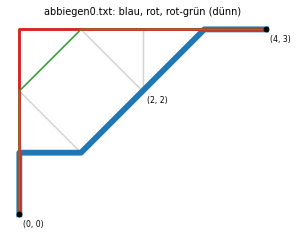

In [ ]:
import matplotlib.pyplot as plt

BLAU = [(0, 0), (0, 1), (1, 1), (2, 2), (3, 3), (4, 3)]
ROT = [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (4, 3)]
ROT_GRUEN = [(0, 0), (0, 1), (0, 2), (1, 3), (2, 3), (3, 3), (4, 3)]


def zeichne(achse, start, ziel, strassen, wege, titel):
    """wege: Liste von (Liste von Punkten, Farbe, Linienbreite)"""
    for a, b in strassen:
        achse.plot([a[0], b[0]], [a[1], b[1]], color='lightgray', linewidth=1.5, zorder=1)
    for weg, farbe, breite in wege:
        achse.plot([p[0] for p in weg], [p[1] for p in weg], color=farbe, linewidth=breite, zorder=2)
    achse.plot([start[0], ziel[0]], [start[1], ziel[1]], 'ko', markersize=5, zorder=3)
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=10)
    achse.axis('off')


start0, ziel0, strassen0 = lies(datei(0))
fig, achse = plt.subplots(figsize=(5, 4))
zeichne(achse, start0, ziel0, strassen0, [(BLAU, 'tab:blue', 6), (ROT, 'tab:red', 3), (ROT_GRUEN, 'tab:green', 1.5)],
        'abbiegen0.txt: blau, rot, rot-grün (dünn)')
for p in strassen0[0][0], (2, 2), (4, 3):
    achse.annotate(str(p), p, textcoords='offset points', xytext=(4, -12), fontsize=8)
plt.show()

## Schritt 2: Wann biegt Bilal ab?

Die Richtung einer Straße von `a` nach `b` ist der Vektor `(dx, dy) = (b[0] - a[0], b[1] - a[1])`. Zwei Straßen zeigen in dieselbe
Richtung, wenn ein Vektor ein **positives** Vielfaches des anderen ist, zum Beispiel `(2, 1)` und `(4, 2)`. Um das einfach vergleichen
zu können, teilen wir beide Zahlen durch ihren größten gemeinsamen Teiler: Aus `(4, 2)` wird `(2, 1)`, aus `(0, 3)` wird `(0, 1)`. Weil
`math.gcd` immer eine positive Zahl liefert, bleiben die Vorzeichen erhalten: `(-2, -1)` (die Gegenrichtung) bleibt `(-2, -1)`.

Mit Steigungen `dy / dx` ginge es auch, aber senkrechte Straßen (`dx = 0`) bräuchten eine Sonderbehandlung, Kommazahlen sind ungenau,
und die Gegenrichtung hätte dieselbe Steigung.

In [ ]:
from math import gcd


def richtung(a, b):
    dx = b[0] - a[0]
    dy = b[1] - a[1]
    teiler = gcd(dx, dy)
    return (dx // teiler, dy // teiler)


def abgebogen(a, b, c):
    """Biegt Bilal ab, wenn er von a nach b und dann von b nach c fährt?"""
    return richtung(a, b) != richtung(b, c)


print(richtung((0, 0), (4, 2)), richtung((4, 2), (6, 3)), richtung((6, 3), (4, 2)), richtung((5, 1), (5, 4)))
print(abgebogen((0, 0), (0, 1), (0, 2)), abgebogen((0, 1), (1, 1), (2, 2)), abgebogen((1, 1), (2, 2), (3, 3)),
      abgebogen((0, 1), (0, 2), (0, 1)))

(2, 1) (2, 1) (-2, -1) (0, 1)
False True False True


Geradeaus von `(0,0)` über `(0,1)` nach `(0,2)`; abgebogen von waagerecht auf schräg bei `(1,1)`; geradeaus auf der Schrägen über
`(2,2)`; und Umkehren bei `(0,2)` zählt als Abbiegen (Richtung `(0, -1)` statt `(0, 1)`).

Damit können wir für einen Weg (Liste von Kreuzungen) die Länge und die Zahl der Abbiegungen ausrechnen und die drei Wege aus der
Aufgabe nachprüfen:

In [ ]:
def weglaenge(weg):
    return sum(laenge(weg[i], weg[i + 1]) for i in range(len(weg) - 1))


def abbiegungen(weg):
    return sum(1 for i in range(len(weg) - 2) if abgebogen(weg[i], weg[i + 1], weg[i + 2]))


kurz0 = weglaenge(BLAU)
for name, weg in [('blau', BLAU), ('rot', ROT), ('rot-grün', ROT_GRUEN)]:
    print('%-9s Länge %.3f, %d Abbiegungen, %+.1f %% gegenüber blau' % (name, weglaenge(weg), abbiegungen(weg),
                                                                     (weglaenge(weg) / kurz0 - 1) * 100))

blau      Länge 5.828, 3 Abbiegungen, +0.0 % gegenüber blau
rot       Länge 7.000, 1 Abbiegungen, +20.1 % gegenüber blau
rot-grün  Länge 6.414, 2 Abbiegungen, +10.1 % gegenüber blau


Wie in der Aufgabe: 3 + 2·√2 ≈ 5,83 mit drei Abbiegungen, 7 mit einer, 5 + √2 ≈ 6,41 mit zwei. Der rot-grüne Weg ist genau genommen
um 10,05% länger als der blaue. Bei einer erlaubten Verlängerung von genau 10% ist er also schon zu lang.

## Schritt 3: Der kürzeste Weg (Dijkstra)

Für die Grenze brauchen wir zuerst die Länge des kürzesten Weges. Das ist der klassische Dijkstra-Algorithmus: In der Warteschlange
stehen Paare `(entfernung, kreuzung)`. Wir nehmen immer das Paar mit der kleinsten Entfernung heraus. Wird eine Kreuzung zum ersten Mal
herausgenommen, ist ihre Entfernung endgültig, und wir tragen ihre Nachbarn ein.

In [ ]:
import heapq


def kuerzester_weg(start, ziel, strassen):
    nachbarn = nachbarn_von(strassen)
    fertig = {}                                   # Kreuzung -> endgültige Entfernung
    schlange = [(0, start)]
    while schlange:
        entfernung, p = heapq.heappop(schlange)
        if p in fertig:                           # schon kürzer erreicht
            continue
        fertig[p] = entfernung
        for q in nachbarn[p]:
            if q not in fertig:
                heapq.heappush(schlange, (entfernung + laenge(p, q), q))
    return fertig.get(ziel, math.inf)


for nr in range(4):
    print('abbiegen%d.txt: kürzester Weg %.3f' % (nr, kuerzester_weg(*lies(datei(nr)))))

abbiegen0.txt: kürzester Weg 5.828
abbiegen1.txt: kürzester Weg 17.122
abbiegen2.txt: kürzester Weg 10.886
abbiegen3.txt: kürzester Weg 17.122


## Schritt 4: Dijkstra über Zustände

Jetzt kommt das Abbiegen dazu. Ein Zustand ist ein Tupel `(u, v, k)`: Bilal ist zuletzt von `u` nach `v` gefahren und hat bisher
`k`-mal abgebogen. In der Warteschlange stehen `(länge, k, u, v, vorgänger)`. Am Start gibt es noch keine Richtung; die erste Straße
kostet darum keine Abbiegung.

Wie viele Abbiegungen müssen wir höchstens betrachten? Die Lösungshinweise zeigen: Fährt ein Weg zweimal durch dieselbe Kreuzung, kann
man die Schleife dazwischen weglassen. Der Weg wird kürzer und bekommt nicht mehr Abbiegungen (in der Schleife wurde mindestens einmal
abgebogen, an der Kreuzung kommt höchstens eine Abbiegung dazu). Ein Weg ohne doppelte Kreuzung hat bei `n` Kreuzungen höchstens `n`
Kreuzungen und damit höchstens `n - 2` Abbiegungen. Mehr brauchen wir nicht.

Für jeden fertigen Zustand merken wir uns den Vorgänger, damit wir den Weg später zurückverfolgen können. `zustaende` zählt, wie viele
Zustände fertig werden.

In [ ]:
def beste_wege(start, ziel, strassen):
    """Liefert (am_ziel, vorgaenger, zustaende); am_ziel ist eine Liste von (länge, k, zustand) für alle Zustände am Ziel."""
    nachbarn = nachbarn_von(strassen)
    hoechstens = len(nachbarn) - 2
    vorgaenger = {}                               # fertiger Zustand -> Zustand davor (None am Start)
    am_ziel = []
    schlange = []
    for v in nachbarn[start]:
        heapq.heappush(schlange, (laenge(start, v), 0, start, v, None))
    while schlange:
        l, k, u, v, vorher = heapq.heappop(schlange)
        if (u, v, k) in vorgaenger:               # schon fertig
            continue
        vorgaenger[(u, v, k)] = vorher
        if v == ziel:
            am_ziel.append((l, k, (u, v, k)))
        for w in nachbarn[v]:
            k2 = k + 1 if abgebogen(u, v, w) else k
            if k2 <= hoechstens and (v, w, k2) not in vorgaenger:
                heapq.heappush(schlange, (l + laenge(v, w), k2, v, w, (u, v, k)))
    return am_ziel, vorgaenger, len(vorgaenger)


am_ziel0, vorgaenger0, zustaende0 = beste_wege(start0, ziel0, strassen0)
print(zustaende0, 'fertige Zustände,', len(am_ziel0), 'davon am Ziel')
kuerzeste0 = {}
for l, k, zustand in am_ziel0:
    if k not in kuerzeste0:                       # der erste ist der kürzeste (Dijkstra)
        kuerzeste0[k] = l
for k in sorted(kuerzeste0):
    print('genau %d-mal abbiegen: kürzester Weg %.3f' % (k, kuerzeste0[k]))

202 fertige Zustände, 8 davon am Ziel
genau 1-mal abbiegen: kürzester Weg 7.000
genau 2-mal abbiegen: kürzester Weg 6.414
genau 3-mal abbiegen: kürzester Weg 5.828
genau 4-mal abbiegen: kürzester Weg 6.414
genau 5-mal abbiegen: kürzester Weg 7.828
genau 6-mal abbiegen: kürzester Weg 7.828
genau 7-mal abbiegen: kürzester Weg 9.243
genau 8-mal abbiegen: kürzester Weg 9.828


Möglich wären 28 Fahrtrichtungen (14 Straßen, je zwei Richtungen) mal 9 Werte für `k` (0 bis 8), also 252 Zustände; fertig werden
202, die anderen sind nicht erreichbar. Am Ziel sehen wir die Wege aus der Aufgabe wieder: 7 mit einer Abbiegung, 6,414 mit zwei und 5,828 mit drei. Mit mehr
Abbiegungen wird es nicht kürzer, aber Dijkstra findet solche Umwege natürlich auch. Mit null Abbiegungen kommt man nicht zum Ziel.

## Schritt 5: Weg zurückverfolgen und vorschlagen

Vom Zustand am Ziel gehen wir über `vorgaenger` zurück bis zum Start und sammeln die Kreuzungen ein. Für Bilal ist eine
**Wegbeschreibung** praktischer als die lange Liste: nur der Start, die Punkte, an denen er abbiegt, und das Ziel.

`vorschlag` macht dann Schritt 4 der Idee: Grenze ausrechnen, unter den Wegen am Ziel, die nicht zu lang sind, den mit den wenigsten
Abbiegungen und davon den kürzesten nehmen. Weil die Längen Kommazahlen sind (√2 ist nicht exakt darstellbar), geben wir der Grenze
eine winzige Zugabe von `1e-9`, damit der kürzeste Weg bei +0% sicher selbst dazugehört.

In [ ]:
def weg_zu(zustand, vorgaenger):
    weg = []
    while zustand is not None:
        u, v, k = zustand
        weg.append(v)
        if vorgaenger[zustand] is None:
            weg.append(u)                         # der Start
        zustand = vorgaenger[zustand]
    weg.reverse()
    return weg


def beschreibung(weg):
    punkte = [weg[0]] + [weg[i + 1] for i in range(len(weg) - 2) if abgebogen(weg[i], weg[i + 1], weg[i + 2])] + [weg[-1]]
    return ' -> '.join('(%d,%d)' % p for p in punkte)


def vorschlag(am_ziel, prozent):
    """(länge, k, zustand) des Vorschlags und die kürzeste Länge."""
    kuerzeste = min(l for l, k, zustand in am_ziel)
    grenze = kuerzeste * (1 + prozent / 100) + 1e-9
    erlaubt = [(k, l, zustand) for l, k, zustand in am_ziel if l <= grenze]
    k, l, zustand = min(erlaubt)                  # wenigste Abbiegungen, dann kürzeste Länge
    return l, k, zustand, kuerzeste


for prozent in 30, 15, 10, 0:
    l, k, zustand, kuerzeste = vorschlag(am_ziel0, prozent)
    weg = weg_zu(zustand, vorgaenger0)
    print('+%2d %%: %d-mal abbiegen, Länge %.3f (%+.1f %%)  %s' % (prozent, k, l, (l / kuerzeste - 1) * 100, beschreibung(weg)))
    assert abbiegungen(weg) == k and abs(weglaenge(weg) - l) < 1e-9

+30 %: 1-mal abbiegen, Länge 7.000 (+20.1 %)  (0,0) -> (0,3) -> (4,3)
+15 %: 2-mal abbiegen, Länge 6.414 (+10.1 %)  (0,0) -> (0,2) -> (1,3) -> (4,3)
+10 %: 3-mal abbiegen, Länge 5.828 (+0.0 %)  (0,0) -> (0,1) -> (1,1) -> (3,3) -> (4,3)
+ 0 %: 3-mal abbiegen, Länge 5.828 (+0.0 %)  (0,0) -> (0,1) -> (1,1) -> (3,3) -> (4,3)


Genau Bilals Wege: bei +30% der rote (einmal abbiegen bei `(0,3)`), bei +15% der rot-grüne, bei +10% und +0% der blaue. Die
`assert`-Zeile rechnet für jeden zurückverfolgten Weg Länge und Abbiegungen mit den Funktionen aus Schritt 2 nach.

Ein Programm für Bilal würde die Verlängerung einlesen, zum Beispiel mit `prozent = float(input('Verlängerung in Prozent: '))`. Im
Notebook setzen wir die Werte direkt ein.

## Schritt 6: Überholte Zustände weglassen

Schritt 4 betrachtet viele Zustände, die nichts bringen können. Nehmen wir an, Dijkstra nimmt den Zustand `(u, v, 5)` heraus, aber
`(u, v, 3)` war schon fertig. Dann war `(u, v, 3)` nicht länger (Dijkstra nimmt nach der Länge heraus) **und** hatte weniger
Abbiegungen. Von derselben Straße aus geht es mit denselben Möglichkeiten weiter; alles, was man aus `(u, v, 5)` machen kann, geht von
`(u, v, 3)` aus mindestens genauso gut. Der neue Zustand ist **überholt**.

Wir merken uns deshalb für jede Fahrtrichtung `(u, v)` die kleinste Zahl von Abbiegungen, mit der sie schon fertig wurde. Ein Zustand
wird nur noch fertig, wenn er **weniger** Abbiegungen hat. Die Obergrenze `n - 2` brauchen wir dann gar nicht mehr.

In [ ]:
def beste_wege_v2(start, ziel, strassen):
    nachbarn = nachbarn_von(strassen)
    wenigste = {}                                 # (u, v) -> kleinstes k, mit dem diese Fahrtrichtung fertig wurde
    vorgaenger = {}
    am_ziel = []
    schlange = []
    for v in nachbarn[start]:
        heapq.heappush(schlange, (laenge(start, v), 0, start, v, None))
    while schlange:
        l, k, u, v, vorher = heapq.heappop(schlange)
        if (u, v) in wenigste and wenigste[(u, v)] <= k:      # überholt
            continue
        wenigste[(u, v)] = k
        vorgaenger[(u, v, k)] = vorher
        if v == ziel:
            am_ziel.append((l, k, (u, v, k)))
        for w in nachbarn[v]:
            k2 = k + 1 if abgebogen(u, v, w) else k
            if (v, w) not in wenigste or wenigste[(v, w)] > k2:
                heapq.heappush(schlange, (l + laenge(v, w), k2, v, w, (u, v, k)))
    return am_ziel, vorgaenger, len(vorgaenger)


def vorschlaege(am_ziel):
    """Für +30, +15, +10 und +0 Prozent: (Abbiegungen, gerundete Länge)."""
    ergebnis = []
    for prozent in 30, 15, 10, 0:
        l, k, zustand, kuerzeste = vorschlag(am_ziel, prozent)
        ergebnis.append((k, round(l, 6)))
    return ergebnis


print('Beispiel  Zustände v1  Zustände v2  Fahrtrichtungen')
for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    am_ziel1, vorgaenger1, zustaende1 = beste_wege(start, ziel, strassen)
    am_ziel2, vorgaenger2, zustaende2 = beste_wege_v2(start, ziel, strassen)
    assert vorschlaege(am_ziel1) == vorschlaege(am_ziel2)
    assert abs(min(l for l, k, z in am_ziel2) - kuerzester_weg(start, ziel, strassen)) < 1e-9
    print('%8d %12d %12d %16d' % (nr, zustaende1, zustaende2, 2 * len(strassen)))

Beispiel  Zustände v1  Zustände v2  Fahrtrichtungen
       0          202           39               28
       1        20884          571              296
       2        24396          469              324
       3        12806          430              230


Die zweite Fassung braucht nur noch einen Bruchteil der Zustände, im Schnitt nicht einmal zwei je Fahrtrichtung, und liefert dieselben
Vorschläge (`assert`). Die kürzeste Länge am Ziel ist auch dieselbe wie bei Dijkstra aus Schritt 3: Den kürzesten Weg bekommen wir
nebenbei mit. Ab jetzt rechnen wir mit `beste_wege_v2`.

## Schritt 7: Alle Beispiele

Für jedes Beispiel und jede Verlängerung: Abbiegungen, Länge, tatsächliche Verlängerung, die Wegbeschreibung und zum Vergleich die
Zahlen aus Abschnitt 3.2 der Lösungshinweise.

In [ ]:
HINWEISE = {0: [(1, 7.000), (2, 6.414), (3, 5.828), (3, 5.828)],
            1: [(5, 19.122), (5, 19.122), (6, 17.301), (7, 17.122)],
            2: [(4, 13.064), (5, 11.064), (5, 11.064), (6, 10.886)],
            3: [(4, 17.886), (4, 17.886), (4, 17.886), (7, 17.122)]}

ergebnisse = {}
wege = {}
for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    am_ziel, vorgaenger, zustaende = beste_wege_v2(start, ziel, strassen)
    print('abbiegen%d.txt' % nr)
    for i, prozent in enumerate([30, 15, 10, 0]):
        l, k, zustand, kuerzeste = vorschlag(am_ziel, prozent)
        weg = weg_zu(zustand, vorgaenger)
        wege[(nr, prozent)] = weg
        ergebnisse[(nr, prozent)] = (k, round(l, 3))
        print('  +%2d %%: %d-mal abbiegen, Länge %6.3f (%+5.1f %%)   Hinweise: %d-mal, %6.3f' % (
            prozent, k, l, (l / kuerzeste - 1) * 100, HINWEISE[nr][i][0], HINWEISE[nr][i][1]))
        print('         ' + beschreibung(weg))
    print()

abbiegen0.txt
  +30 %: 1-mal abbiegen, Länge  7.000 (+20.1 %)   Hinweise: 1-mal,  7.000
         (0,0) -> (0,3) -> (4,3)
  +15 %: 2-mal abbiegen, Länge  6.414 (+10.1 %)   Hinweise: 2-mal,  6.414
         (0,0) -> (0,2) -> (1,3) -> (4,3)
  +10 %: 3-mal abbiegen, Länge  5.828 ( +0.0 %)   Hinweise: 3-mal,  5.828
         (0,0) -> (0,1) -> (1,1) -> (3,3) -> (4,3)
  + 0 %: 3-mal abbiegen, Länge  5.828 ( +0.0 %)   Hinweise: 3-mal,  5.828
         (0,0) -> (0,1) -> (1,1) -> (3,3) -> (4,3)

abbiegen1.txt
  +30 %: 5-mal abbiegen, Länge 19.122 (+11.7 %)   Hinweise: 5-mal, 19.122
         (0,0) -> (1,1) -> (5,1) -> (11,4) -> (11,3) -> (14,3) -> (14,0)
  +15 %: 5-mal abbiegen, Länge 19.122 (+11.7 %)   Hinweise: 5-mal, 19.122
         (0,0) -> (1,1) -> (5,1) -> (11,4) -> (11,3) -> (14,3) -> (14,0)
  +10 %: 6-mal abbiegen, Länge 17.301 ( +1.0 %)   Hinweise: 6-mal, 17.301
         (0,0) -> (1,1) -> (5,1) -> (9,3) -> (10,2) -> (10,1) -> (14,1) -> (14,0)
  + 0 %: 7-mal abbiegen, Länge 17.122 ( +0.0 %) 

**Vergleich mit den Lösungshinweisen:** Alle 16 Werte stimmen überein, Abbiegungen und Längen (geprüft am Ende des Generators). Die
Lösungshinweise verlangen optimale Ergebnisse, also wirklich die kleinste Zahl von Abbiegungen; dass wir dann den kürzesten dieser Wege
nehmen, empfehlen sie, verlangen es aber nicht.

Auffällig ist `abbiegen3.txt`: Schon mit 4,5% Umweg spart Bilal drei von sieben Abbiegungen. Bei `abbiegen1.txt` bleibt es auch bei
+30% bei fünf Abbiegungen, weil es gar keinen Weg mit weniger gibt (siehe unten). In der Zeichnung ist jede Zeile ein Beispiel, jede Spalte eine Verlängerung.

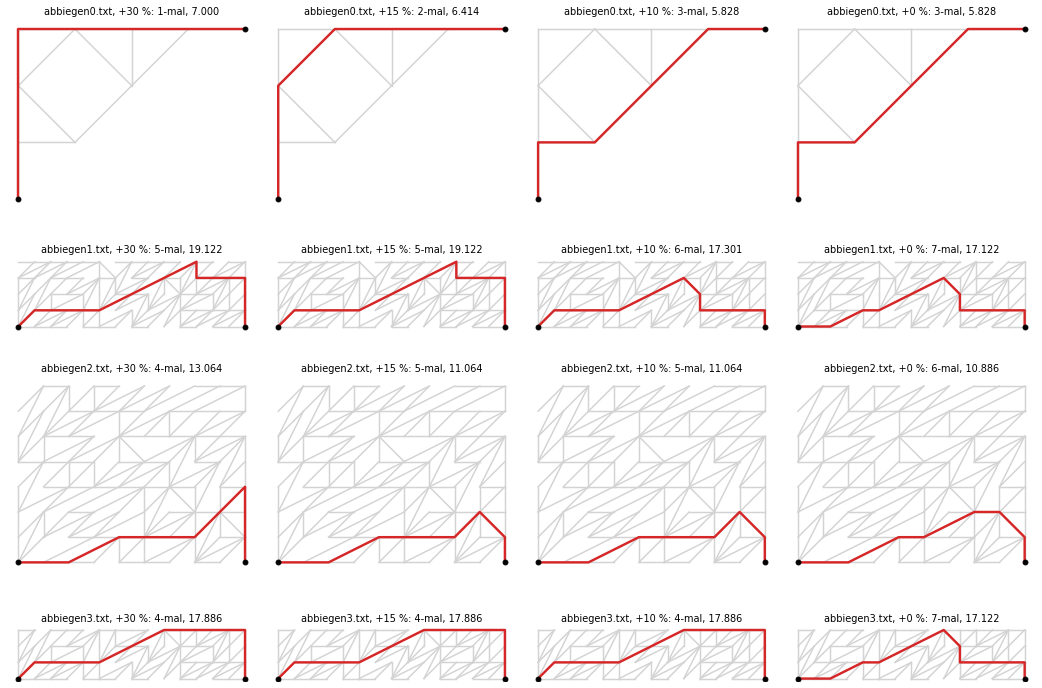

In [ ]:
fig, achsen = plt.subplots(4, 4, figsize=(15, 11))
for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    for i, prozent in enumerate([30, 15, 10, 0]):
        k, l = ergebnisse[(nr, prozent)]
        zeichne(achsen[nr][i], start, ziel, strassen, [(wege[(nr, prozent)], 'tab:red', 2.5)],
                'abbiegen%d.txt, +%d %%: %d-mal, %.3f' % (nr, prozent, k, l))
plt.tight_layout()
plt.show()

Wie viele Abbiegungen kosten wie viel Umweg? Die folgende Zelle zeigt für jedes Beispiel die Wege, bei denen eine Abbiegung weniger
einen längeren Weg kostet (jeweils der kürzeste Weg mit höchstens so vielen Abbiegungen). Daraus kann man für jede Verlängerung den
Vorschlag ablesen.

In [ ]:
for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    am_ziel, vorgaenger, zustaende = beste_wege_v2(start, ziel, strassen)
    kuerzeste = min(l for l, k, z in am_ziel)
    stufen = []
    bisher = math.inf
    for k, l in sorted((k, l) for l, k, zustand in am_ziel):
        if l < bisher - 1e-9:
            bisher = l
            stufen.append('%d: %.3f (%+.1f %%)' % (k, l, (l / kuerzeste - 1) * 100))
    print('abbiegen%d.txt  ' % nr + ',  '.join(stufen))

abbiegen0.txt  1: 7.000 (+20.1 %),  2: 6.414 (+10.1 %),  3: 5.828 (+0.0 %)
abbiegen1.txt  5: 19.122 (+11.7 %),  6: 17.301 (+1.0 %),  7: 17.122 (+0.0 %)
abbiegen2.txt  3: 15.944 (+46.5 %),  4: 13.064 (+20.0 %),  5: 11.064 (+1.6 %),  6: 10.886 (+0.0 %)
abbiegen3.txt  4: 17.886 (+4.5 %),  5: 17.708 (+3.4 %),  6: 17.301 (+1.0 %),  7: 17.122 (+0.0 %)


`sorted` sortiert Tupel wie Wörter im Lexikon: zuerst nach dem ersten Eintrag (hier `k`), bei Gleichstand nach dem zweiten (der Länge).
Darum stehen die Paare hier in der Reihenfolge `(k, l)`.

Die erste Stufe ist die kleinste Zahl von Abbiegungen, mit der man überhaupt ans Ziel kommt: bei `abbiegen1.txt` fünf. Bei
`abbiegen2.txt` würde Bilal mit drei Abbiegungen auskommen, wenn er 46,5% Umweg in Kauf nähme.

## Schritt 8: Probe durch Durchprobieren

Bei kleinen Karten können wir alle Wege ohne doppelte Kreuzung aufzählen (Tiefensuche mit Zurücknehmen) und für jede Zahl `k` den
kürzesten Weg mit höchstens `k` Abbiegungen bestimmen. Nach der Überlegung in Schritt 4 reichen diese Wege aus. Wir vergleichen mit den
Stufen von `beste_wege_v2`: zuerst bei `abbiegen0.txt`, dann bei 300 zufälligen Karten auf einem 4×4-Gitter (waagerechte, senkrechte und
höchstens eine schräge Straße je Kästchen, damit sich keine Straßen kreuzen; Start `(0,0)`, Ziel `(3,3)`). Karten, bei denen das Ziel
nicht erreichbar ist, überspringen wir.

In [ ]:
import random


def alle_wege(weg, ziel, nachbarn, gefunden):
    """Hängt an gefunden alle Wege ohne doppelte Kreuzung an, die mit weg beginnen und am Ziel enden."""
    p = weg[-1]
    if p == ziel:
        gefunden.append(list(weg))
        return
    for q in nachbarn[p]:
        if q not in weg:
            weg.append(q)
            alle_wege(weg, ziel, nachbarn, gefunden)
            weg.pop()                             # zurücknehmen


def stufen_durchprobieren(start, ziel, strassen):
    """Für k = 0, 1, 2, ...: kürzester Weg mit höchstens k Abbiegungen (gerundet), solange es kürzer wird."""
    beste = {}
    wege_liste = []
    alle_wege([start], ziel, nachbarn_von(strassen), wege_liste)
    for weg in wege_liste:
        k = abbiegungen(weg)
        beste[k] = min(beste.get(k, math.inf), weglaenge(weg))
    return stufen_aus(beste), len(wege_liste)


def stufen_aus(beste):
    stufen = []
    bisher = math.inf
    for k in sorted(beste):
        if beste[k] < bisher - 1e-9:
            bisher = beste[k]
            stufen.append((k, round(bisher, 6)))
    return stufen


def stufen_dijkstra(start, ziel, strassen):
    beste = {}
    for l, k, zustand in beste_wege_v2(start, ziel, strassen)[0]:
        beste[k] = min(beste.get(k, math.inf), l)
    return stufen_aus(beste)


stufen0, anzahl0 = stufen_durchprobieren(start0, ziel0, strassen0)
print('abbiegen0.txt:', anzahl0, 'Wege ohne doppelte Kreuzung, Stufen', stufen0)
assert stufen0 == stufen_dijkstra(start0, ziel0, strassen0)

zufall = random.Random(1)
verglichen = 0
meiste_wege = 0
for versuch in range(300):
    strassen = []
    for x in range(4):
        for y in range(4):
            if x < 3 and zufall.random() < 0.7:
                strassen.append(((x, y), (x + 1, y)))
            if y < 3 and zufall.random() < 0.7:
                strassen.append(((x, y), (x, y + 1)))
            if x < 3 and y < 3:
                wahl = zufall.random()
                if wahl < 0.25:
                    strassen.append(((x, y), (x + 1, y + 1)))
                elif wahl < 0.5:
                    strassen.append(((x + 1, y), (x, y + 1)))
    if (0, 0) not in nachbarn_von(strassen) or kuerzester_weg((0, 0), (3, 3), strassen) == math.inf:
        continue                                  # Start ohne Straße oder Ziel nicht erreichbar
    stufen, anzahl = stufen_durchprobieren((0, 0), (3, 3), strassen)
    assert stufen == stufen_dijkstra((0, 0), (3, 3), strassen), versuch
    verglichen += 1
    meiste_wege = max(meiste_wege, anzahl)
print(verglichen, 'zufällige Karten verglichen (bis zu', meiste_wege, 'Wege je Karte), alles gleich')

abbiegen0.txt: 22 Wege ohne doppelte Kreuzung, Stufen [(1, 7.0), (2, 6.414214), (3, 5.828427)]
248 zufällige Karten verglichen (bis zu 438 Wege je Karte), alles gleich


Bei den großen Beispielen wäre Durchprobieren hoffnungslos: Die Zahl der Wege wächst mit der Größe der Karte exponentiell.

## Zum Schluss: Mit MiniZinc

Kann MiniZinc die Aufgabe lösen? Wege durch einen Graphen beschreibt man in MiniZinc als **Fluss**: Für jede Fahrtrichtung `e` (jede
Straße zweimal, einmal in jede Richtung) gibt es eine Variable `x[e]` (1 = Bilal fährt sie). An jeder Kreuzung fährt Bilal so oft hinaus
wie hinein, am Start einmal mehr hinaus, am Ziel einmal mehr hinein. Neu ist `(v = s)`: Ein Vergleich zählt in einer Rechnung als 1, wenn
er stimmt, sonst als 0.

Für das Abbiegen reicht `x` nicht, denn es kommt auf die **Reihenfolge** an. Darum gibt es für jeden Übergang `p` (erst Fahrtrichtung
`erste[p]` in eine Kreuzung hinein, dann `zweite[p]` hinaus) eine Variable `y[p]`. Nach jeder gefahrenen Fahrtrichtung folgt genau ein
Übergang, vor jeder liegt genau einer (am Start und am Ziel keiner). Die Abbiegungen sind die Übergänge mit `abb[p] = 1`; das berechnet
Python mit `richtung` aus Schritt 2.

Könnten zu den Variablen auch Kreise gehören, die gar nicht mit dem Weg zusammenhängen? Die Bedingungen würden sie erlauben. Ein Kreis
kommt aber nicht ohne Abbiegen zurück zu seinem Anfang. Lässt man ihn weg, hat man weniger Abbiegungen und einen kürzeren Weg. Eine
beste Lösung enthält also keinen.

Gesucht ist zuerst die kleinste Zahl von Abbiegungen und dann die kleinste Länge. Beides steckt in **einem** Ziel:
`100000000 * abbiegungen + weglaenge`. Weil jeder erlaubte Weg kürzer als 100 ist (100000000 Millionstel), zählt eine Abbiegung mehr
als jeder Längenunterschied. Die Längen sind ganze Zahlen in Millionstel; die Grenze bekommt eine kleine Zugabe von 100 Millionstel
gegen Rundungsfehler (wie die `1e-9` in Schritt 5). `fix(x[e])` in der Ausgabe ist der Wert der Variablen in der Lösung.
```minizinc
int: n;                                   % Zahl der Kreuzungen (Nummern 1..n)
int: m;                                   % Zahl der Fahrtrichtungen (jede Straße zweimal)
int: P;                                   % Zahl der Übergänge (erst Fahrtrichtung e, dann f)
int: s;                                   % Start
int: t;                                   % Ziel
array[1..m] of 1..n: von;
array[1..m] of 1..n: nach;
array[1..m] of int: laenge;               % in Millionstel, gerundet
array[1..P] of 1..m: erste;
array[1..P] of 1..m: zweite;
array[1..P] of 0..1: abb;                 % 1: bei diesem Übergang wird abgebogen
int: grenze;                              % so lang darf der Weg höchstens sein

array[1..m] of var 0..1: x;               % x[e] = 1: Bilal fährt e
array[1..P] of var 0..1: y;               % y[p] = 1: Bilal fährt erste[p] und gleich danach zweite[p]

% an jeder Kreuzung: so oft hinaus wie hinein, am Start einmal mehr hinaus, am Ziel einmal mehr hinein
constraint forall(v in 1..n)(
    sum(e in 1..m where von[e] = v)(x[e]) - sum(e in 1..m where nach[e] = v)(x[e]) = (v = s) - (v = t));
% nach jeder gefahrenen Fahrtrichtung geht es auf genau einer weiter (außer am Ziel)
constraint forall(e in 1..m)(
    sum(p in 1..P where erste[p] = e)(y[p]) = if nach[e] = t then 0 else x[e] endif);
% vor jeder gefahrenen Fahrtrichtung kam genau eine (außer am Start)
constraint forall(f in 1..m)(
    sum(p in 1..P where zweite[p] = f)(y[p]) = if von[f] = s then 0 else x[f] endif);

var int: weglaenge = sum(e in 1..m)(laenge[e] * x[e]);
var int: abbiegungen = sum(p in 1..P)(abb[p] * y[p]);
constraint weglaenge <= grenze;

solve minimize 100000000 * abbiegungen + weglaenge;
output ["Abbiegungen: \(abbiegungen), Länge: \(weglaenge)\n",
        concat(["\(von[e])->\(nach[e]) " | e in 1..m where fix(x[e]) = 1]), "\n"];
```

Die Datendatei erzeugt `als_dzn`. Die Kreuzungen werden dabei nach ihren Koordinaten durchnummeriert.

In [ ]:
def als_dzn(start, ziel, strassen, prozent):
    kreuzungen = sorted(nachbarn_von(strassen))
    nummer = {}
    for i in range(len(kreuzungen)):
        nummer[kreuzungen[i]] = i + 1
    richtungen = strassen + [(b, a) for a, b in strassen]
    erste, zweite, abb = [], [], []
    for e in range(len(richtungen)):
        for f in range(len(richtungen)):
            a, b = richtungen[e]
            c, d = richtungen[f]
            if b == c:                            # f beginnt, wo e endet
                erste.append(e + 1)
                zweite.append(f + 1)
                abb.append(1 if abgebogen(a, b, d) else 0)
    grenze = int(kuerzester_weg(start, ziel, strassen) * (1 + prozent / 100) * 1000000) + 100
    zeilen = ['n = %d;' % len(kreuzungen), 'm = %d;' % len(richtungen), 'P = %d;' % len(erste),
              's = %d;' % nummer[start], 't = %d;' % nummer[ziel],
              'von = %s;' % [nummer[a] for a, b in richtungen], 'nach = %s;' % [nummer[b] for a, b in richtungen],
              'laenge = %s;' % [round(1000000 * laenge(a, b)) for a, b in richtungen],
              'erste = %s;' % erste, 'zweite = %s;' % zweite, 'abb = %s;' % abb, 'grenze = %d;' % grenze]
    return '\n'.join(zeilen), kreuzungen


dzn0, kreuzungen0 = als_dzn(start0, ziel0, strassen0, 15)
print(dzn0)
print('Kreuzungen:', kreuzungen0)

n = 10;
m = 28;
P = 90;
s = 1;
t = 10;
von = [1, 2, 3, 2, 3, 3, 4, 5, 6, 6, 7, 7, 8, 9, 2, 3, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10];
nach = [2, 3, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 1, 2, 3, 2, 3, 3, 4, 5, 6, 6, 7, 7, 8, 9];
laenge = [1000000, 1000000, 1000000, 1000000, 1414214, 1414214, 1000000, 1414214, 1414214, 1000000, 1000000, 1414214, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1414214, 1414214, 1000000, 1414214, 1414214, 1000000, 1000000, 1414214, 1000000, 1000000];
erste = [1, 1, 1, 2, 2, 2, 2, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6, 6, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9, 10, 10, 10, 11, 11, 11, 12, 12, 12, 13, 13, 13, 14, 15, 16, 16, 16, 17, 17, 17, 17, 18, 18, 18, 19, 19, 19, 19, 20, 20, 20, 20, 21, 21, 22, 22, 22, 23, 23, 23, 23, 24, 24, 24, 24, 25, 25, 25, 25, 26, 26, 26, 26, 27, 27, 27, 28, 28, 28];
zweite = [2, 4, 15, 3, 5, 6, 16, 7, 17, 8, 18, 19, 8, 18, 19, 9, 10, 20, 21, 9, 10, 20, 21, 11, 12, 22, 23, 11, 12, 22, 23, 13, 24, 25, 13, 24, 25, 14, 26, 27, 14, 26, 27, 

**`abbiegen0.txt` mit +15%** (HiGHS):

**Ausgabe:**

```
Abbiegungen: 2, Länge: 6414214
1->2 2->3 3->6 6->8 8->9 9->10 
----------
==========
```

Die Fahrtrichtungen stehen in der Reihenfolge, in der sie in der Datendatei vorkommen (hier passt das zufällig zur Reihenfolge der
Fahrt). Übersetzt man die Nummern mit der Liste
der Kreuzungen aus der Zelle oben (Nummer 1 ist der erste Eintrag), ist das der rot-grüne Weg mit 2 Abbiegungen und der Länge 6,414214.

Wir lösen das Modell mit **HiGHS**, einem Solver für ganzzahlige lineare Optimierung, der bei MiniZinc dabei ist (Auswahl über
*Solver configuration*), und mit **CP-SAT**. Beide sind bei jedem Beispiel in etwa einer Sekunde fertig und beweisen dabei, dass es
nicht besser geht. Für alle 16 Fälle stimmen Abbiegungen und Länge mit Python überein (geprüft im Generator; die Längen weichen durch das
Runden der einzelnen Straßen höchstens um ein Millionstel ab):

| Beispiel | +30% | +15% | +10% | +0% |
|----------|------|------|------|-----|
| `abbiegen0.txt` | 1-mal, 7.000 | 2-mal, 6.414 | 3-mal, 5.828 | 3-mal, 5.828 |
| `abbiegen1.txt` | 5-mal, 19.122 | 5-mal, 19.122 | 6-mal, 17.301 | 7-mal, 17.122 |
| `abbiegen2.txt` | 4-mal, 13.064 | 5-mal, 11.064 | 5-mal, 11.064 | 6-mal, 10.886 |
| `abbiegen3.txt` | 4-mal, 17.886 | 4-mal, 17.886 | 4-mal, 17.886 | 7-mal, 17.122 |

Mit den anderen Solvern sieht es schlechter aus (gemessen beim Erstellen dieses Notebooks, Zeitlimit 30 Sekunden):

- **Chuffed** löst `abbiegen0.txt` sofort und `abbiegen2.txt` mit +0% in etwa 16 Sekunden. Bei +10% und +15% für `abbiegen2.txt` hat
  er nach 30 Sekunden einen Weg mit der richtigen Zahl von Abbiegungen, aber noch keinen Beweis (bei +15% auch noch nicht den kürzesten).
  Bei `abbiegen1.txt` und `abbiegen3.txt` findet er in 30 Sekunden gar keine Lösung.
- **Gecode** bricht sofort mit einer Fehlermeldung ab: Gecode rechnet nur mit ganzen Zahlen bis etwa 2 Milliarden, und schon die
  größtmögliche Zahl von Abbiegungen mal 100000000 ist größer.

Woran liegt der Unterschied? Das Modell besteht nur aus Summen von 0/1-Variablen und einem Ziel, das eine Summe ist. Für solche Modelle
sind lineare Optimierer wie HiGHS gemacht; sie rechnen mit Kommazahlen-Lösungen als Schranke und sehen so schnell, dass kein Weg mit
weniger Abbiegungen kurz genug sein kann. CP-SAT nutzt dieselbe Technik zusätzlich. Chuffed und Gecode probieren dagegen Variablen
nacheinander aus und erkennen schlecht, wann eine Summe von Hunderten Längen die Grenze überschreiten muss. Unser Dijkstra über Zustände
bleibt trotzdem das passende Werkzeug: Er nutzt aus, dass es um **Wege** geht, und braucht nur ein paar hundert Zustände.

## Für Neugierige

**Das dynamische Programm der Lösungshinweise.** Die Hinweise rechnen zuerst für alle Paare von Kreuzungen `u`, `v` aus, ob man von
`u` nach `v` **ganz ohne Abbiegen** kommt und wie weit das ist (`gerade[u][v]`, sonst unendlich): von `u` aus in jede Richtung so lange
geradeaus fahren, wie es geht. Dann gilt für den kürzesten Weg mit höchstens `k` Abbiegungen vom Start bis `v`:

`A[k][v] = Minimum über alle u von A[k-1][u] + gerade[u][v]`, mit `A[0][v] = gerade[start][v]`.

Der letzte gerade Abschnitt geht von `u` nach `v`; vorher durfte höchstens `k - 1`-mal abgebogen werden. Das kostet `n²` Schritte je
`k`, bei bis zu `n - 2` Werten von `k` also etwa `n³`. Die folgende Zelle rechnet so und vergleicht mit unseren Stufen.

In [ ]:
def gerade_strecken(strassen):
    nachbarn = nachbarn_von(strassen)
    gerade = {u: {u: 0} for u in nachbarn}
    for u in nachbarn:
        for v in nachbarn[u]:
            vorher, jetzt, strecke = u, v, laenge(u, v)
            while True:
                gerade[u][jetzt] = strecke
                weiter = [w for w in nachbarn[jetzt] if not abgebogen(vorher, jetzt, w)]
                if not weiter:                    # es geht nicht mehr geradeaus
                    break
                vorher, jetzt, strecke = jetzt, weiter[0], strecke + laenge(jetzt, weiter[0])
    return gerade


def stufen_hinweise(start, ziel, strassen):
    gerade = gerade_strecken(strassen)
    kreuzungen = list(gerade)
    A = {v: gerade[start].get(v, math.inf) for v in kreuzungen}
    beste = {0: A[ziel]}
    rechenschritte = 0
    for k in range(1, len(kreuzungen) - 1):
        neu = {}
        for v in kreuzungen:
            neu[v] = min(A[u] + gerade[u].get(v, math.inf) for u in kreuzungen)
            rechenschritte += len(kreuzungen)
        A = neu
        beste[k] = A[ziel]
    return stufen_aus(beste), rechenschritte


for nr in range(4):
    start, ziel, strassen = lies(datei(nr))
    stufen, rechenschritte = stufen_hinweise(start, ziel, strassen)
    assert stufen == stufen_dijkstra(start, ziel, strassen)
    print('abbiegen%d.txt: gleiche Stufen, %d Additionen' % (nr, rechenschritte))

abbiegen0.txt: gleiche Stufen, 800 Additionen
abbiegen1.txt: gleiche Stufen, 410625 Additionen
abbiegen2.txt: gleiche Stufen, 480557 Additionen
abbiegen3.txt: gleiche Stufen, 208800 Additionen


Dieselben Ergebnisse. Für die Beispiele sind beide Verfahren schnell; die Zustände von Dijkstra wachsen aber nur mit der Zahl der
Straßen (mal den wenigen Abbiegungszahlen, die sich lohnen), das dynamische Programm mit `n³`.

**Weitere Gedanken**
- **Binäre Suche:** Wer für ein festes `k` den kürzesten Weg mit höchstens `k` Abbiegungen ausrechnet (zum Beispiel mit Schritt 4 und
  Obergrenze `k`), kann das kleinste passende `k` mit binärer Suche finden, weil die Länge mit wachsendem `k` nie größer wird.
- **Abbiegen gewichten:** Eine leichte Kurve stört weniger als ein scharfes Abbiegen. Man könnte jedem Übergang Kosten nach dem Winkel
  geben; Dijkstra über Zustände funktioniert dann genauso, nur zählt `k` keine Abbiegungen mehr, sondern Kosten.
- **Alle besten Wege:** Es kann sehr viele gleich gute Wege geben. Die Hinweise zeigen eine Karte, bei der sich die Zahl der kürzesten
  Wege mit jeder Vergrößerung vervierfacht. Alle aufzuzählen dauert dann zwangsläufig exponentiell lange; einen davon zu finden nicht.